# Assignment 8

Noise drawn from the uniform, Gaussian, Erlang, exponential and Rayleigh pdfs.

Sample: `sample_pattern.png` (flat gray bands and a few shapes). Grain and the shift in brightness show up on a flat field. Gaussian uses mean 0 and variance 0.01, same as imnoise.


In [1]:
%matplotlib inline
import cv2
import numpy as np
import matplotlib.pyplot as plt
from math import factorial, pi, sqrt


# noise drawn from the pdf (inverse transform / box-muller)
# gaussian is what MATLAB imnoise actually has (mean 0, variance 0.01)
# the other four are not in imnoise, so those are checked against numpy

np.random.seed(4)

# parameters on a 0-1 image
UNI_A, UNI_B = 0.0, 0.30
G_MEAN, G_VAR = 0.0, 0.01
ER_A, ER_B = 10, 3          # mean = b/a
EX_A = 4.0                  # mean = 1/a
RY_A, RY_B = 0.0, 0.04      # mean = a + sqrt(pi*b/4)


def uniform_noise(shape, a, b):
    # z = a + (b - a) * U
    u = np.random.rand(*shape)
    return a + (b - a) * u


def gaussian_noise(shape, mean, sigma):
    # Box-Muller
    u1 = np.random.rand(*shape)
    u2 = np.random.rand(*shape)
    u1 = np.maximum(u1, 1e-12)
    return mean + sigma * np.sqrt(-2.0 * np.log(u1)) * np.cos(2.0 * pi * u2)


def erlang_noise(shape, a, b):
    # erlang of order b is the sum of b exponential draws
    z = np.zeros(shape, dtype=np.float64)
    for _ in range(int(b)):
        u = np.random.rand(*shape)
        z += -np.log(1.0 - u) / a
    return z


def exponential_noise(shape, a):
    # z = -ln(1 - U) / a     (erlang with b = 1)
    u = np.random.rand(*shape)
    return -np.log(1.0 - u) / a


def rayleigh_noise(shape, a, b):
    # z = a + sqrt(-b * ln(1 - U))
    u = np.random.rand(*shape)
    return a + np.sqrt(-b * np.log(1.0 - u))


def report(name, data, mean_t, var_t):
    print(f"{name:16} mean {data.mean():7.4f}  (theory {mean_t:7.4f})"
          f"    var {data.var():7.4f}  (theory {var_t:7.4f})")


def add_noise(img01, noise):
    return np.clip(img01 + noise, 0, 1)


def to_u8(img01):
    return np.clip(np.round(img01 * 255), 0, 255).astype(np.uint8)


def plot_pair(ax, mine, other, title, lo, hi, xs, pdf):
    bins = np.linspace(lo, hi, 45)
    ax.hist(mine, bins=bins, density=True, alpha=0.6, label="from pdf")
    ax.hist(other, bins=bins, density=True, alpha=0.45, label="numpy")
    ax.plot(xs, pdf, color="black", linewidth=1.1, label="equation")
    ax.set_title(title)
    ax.set_xlim(lo, hi)
    ax.legend(fontsize=7, loc="upper right")


sample image: sample_pattern.png (320, 480)
gaussian here uses the same mean and variance as imnoise (0, 0.01).
uniform, erlang, exponential and rayleigh are not in imnoise,
so those are compared with numpy's generators.

uniform          mean  0.1499  (theory  0.1500)    var  0.0075  (theory  0.0075)
gaussian         mean -0.0000  (theory  0.0000)    var  0.0100  (theory  0.0100)
erlang           mean  0.3006  (theory  0.3000)    var  0.0300  (theory  0.0300)
exponential      mean  0.2496  (theory  0.2500)    var  0.0619  (theory  0.0625)
rayleigh         mean  0.1772  (theory  0.1772)    var  0.0086  (theory  0.0086)


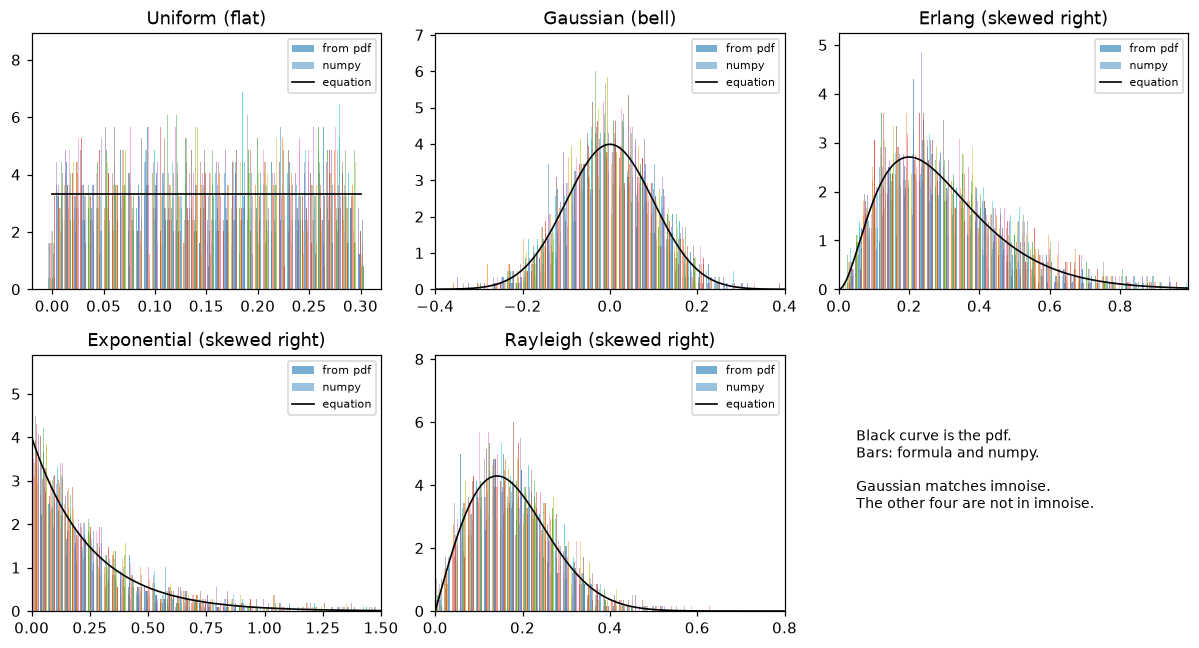

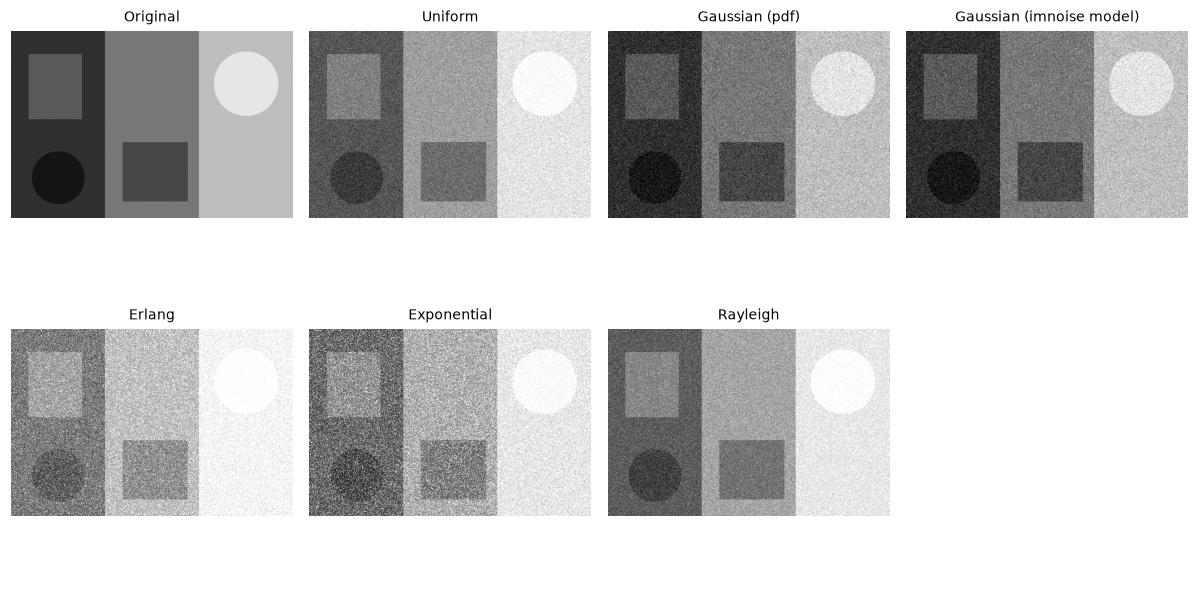

In [2]:
image_path = "sample_pattern.png"
img = cv2.imread(image_path, 0)
print("sample image:", image_path, img.shape)

img01 = img.astype(np.float64) / 255.0
shape = img.shape
g_sigma = sqrt(G_VAR)

uni = uniform_noise(shape, UNI_A, UNI_B)
gauss = gaussian_noise(shape, G_MEAN, g_sigma)
erl = erlang_noise(shape, ER_A, ER_B)
expn = exponential_noise(shape, EX_A)
ray = rayleigh_noise(shape, RY_A, RY_B)

uni_np = np.random.uniform(UNI_A, UNI_B, shape)
gauss_np = np.random.normal(G_MEAN, g_sigma, shape)
erl_np = np.random.gamma(ER_B, 1.0 / ER_A, shape)
exp_np = np.random.exponential(1.0 / EX_A, shape)
ray_np = RY_A + np.random.rayleigh(sqrt(RY_B / 2.0), shape)

print("gaussian here uses the same mean and variance as imnoise (0, 0.01).")
print("uniform, erlang, exponential and rayleigh are not in imnoise,")
print("so those are compared with numpy's generators.")
print()

report("uniform", uni, (UNI_A + UNI_B) / 2.0, (UNI_B - UNI_A) ** 2 / 12.0)
report("gaussian", gauss, G_MEAN, G_VAR)
report("erlang", erl, ER_B / ER_A, ER_B / (ER_A ** 2))
report("exponential", expn, 1.0 / EX_A, 1.0 / (EX_A ** 2))
ry_mean = RY_A + sqrt(pi * RY_B / 4.0)
ry_var = RY_B * (4.0 - pi) / 4.0
report("rayleigh", ray, ry_mean, ry_var)

fig1, axes = plt.subplots(2, 3, figsize=(11, 6))

xs = np.linspace(UNI_A, UNI_B, 200)
plot_pair(axes[0, 0], uni, uni_np, "Uniform (flat)", UNI_A - 0.02, UNI_B + 0.02,
          xs, np.full_like(xs, 1.0 / (UNI_B - UNI_A)))

xs = np.linspace(G_MEAN - 4 * g_sigma, G_MEAN + 4 * g_sigma, 300)
pdf = np.exp(-0.5 * ((xs - G_MEAN) / g_sigma) ** 2) / (g_sigma * sqrt(2 * pi))
plot_pair(axes[0, 1], gauss, gauss_np, "Gaussian (bell)", xs[0], xs[-1], xs, pdf)

hi = ER_B / ER_A + 4 * sqrt(ER_B / (ER_A ** 2))
xs = np.linspace(1e-4, hi, 300)
pdf = (ER_A ** ER_B) * (xs ** (ER_B - 1)) * np.exp(-ER_A * xs) / factorial(ER_B - 1)
plot_pair(axes[0, 2], erl, erl_np, "Erlang (skewed right)", 0, hi, xs, pdf)

hi = 6.0 / EX_A
xs = np.linspace(0, hi, 300)
pdf = EX_A * np.exp(-EX_A * xs)
plot_pair(axes[1, 0], expn, exp_np, "Exponential (skewed right)", 0, hi, xs, pdf)

hi = RY_A + 4 * sqrt(RY_B)
xs = np.linspace(RY_A, hi, 300)
dz = np.maximum(xs - RY_A, 0)
pdf = np.zeros_like(xs)
pos = dz > 0
pdf[pos] = (2.0 / RY_B) * dz[pos] * np.exp(-(dz[pos] ** 2) / RY_B)
plot_pair(axes[1, 1], ray, ray_np, "Rayleigh (skewed right)", RY_A, hi, xs, pdf)

axes[1, 2].axis("off")
axes[1, 2].text(0.05, 0.55,
                "Black curve is the pdf.\n"
                "Bars: formula and numpy.\n\n"
                "Gaussian matches imnoise.\n"
                "The other four are not in imnoise.",
                fontsize=9, va="center")
fig1.tight_layout()

noisy = [
    ("Original", img),
    ("Uniform", to_u8(add_noise(img01, uni))),
    ("Gaussian (pdf)", to_u8(add_noise(img01, gauss))),
    ("Gaussian (imnoise model)", to_u8(add_noise(img01, gauss_np))),
    ("Erlang", to_u8(add_noise(img01, erl))),
    ("Exponential", to_u8(add_noise(img01, expn))),
    ("Rayleigh", to_u8(add_noise(img01, ray))),
]

fig2, axes2 = plt.subplots(2, 4, figsize=(11, 6))
for ax, (title, pic) in zip(axes2.ravel(), noisy):
    ax.imshow(pic, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title, fontsize=9)
    ax.axis("off")
axes2.ravel()[-1].axis("off")
fig2.tight_layout()
plt.show()
